## Load the catalogue

This cell reads the Gaia Catalogue of Nearby Stars (GCNS), `table1c.dat`, into a table with one row per star. The file is fixed-width, meaning each column sits at set character positions rather than being separated by commas. The ReadMe counts positions from 1 and includes both ends, so each range is converted to the `(first - 1, last)` form that `pandas.read_fwf` expects.

The printed counts show how complete each column is. Velocities are often missing because they need a radial velocity (a star's motion towards or away from us), which was mostly measured for brighter stars.

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = "table1c.dat"

# name we will use      ReadMe bytes   units
columns = {
    "ra":       (23, 36),   # deg
    "dec":      (46, 59),   # deg
    "parallax": (69, 77),   # mas
    "gmag":     (123, 130), # mag  (apparent G magnitude)
    "dist50":   (278, 289), # kpc  (note: kpc, not pc)
    "x":        (304, 315), # pc
    "y":        (343, 354), # pc
    "z":        (382, 393), # pc
    "u":        (421, 428), # km/s
    "v":        (448, 455), # km/s
    "w":        (475, 482), # km/s
}

names = []
colspecs = []
for name, (first_byte, last_byte) in columns.items():
    names.append(name)
    colspecs.append((first_byte - 1, last_byte))

# Blank fields (e.g. missing velocities) become NaN automatically.
df = pd.read_fwf(DATA_FILE, colspecs=colspecs, names=names, header=None)

print("Rows loaded:", len(df))
print()
print("How many rows have each column filled in:")
for name in df.columns:
    print(f"   {name:9s} {df[name].notna().sum():7d}")

Rows loaded: 331312

How many rows have each column filled in:
   ra         331312
   dec        331312
   parallax   331312
   gmag       330881
   dist50     331312
   x          331312
   y          331312
   z          331312
   u           82358
   v           82358
   w           82358


## Distance and absolute magnitude

This cell removes objects with no G magnitude, then works out how far away each star is and how bright it really is.

- **Parallax** is the small shift in a star's apparent position as Earth orbits the Sun. Nearer stars shift more, so distance in parsecs is `d = 1000 / parallax`, with parallax in milliarcseconds (mas).
- **Apparent magnitude** `gmag` is how bright a star looks from Earth. Larger numbers mean fainter stars.
- **Absolute magnitude** `M_G` is how bright the star would look from a standard distance of 10 pc, so it measures the star's true brightness: `M_G = gmag - 5 log10(d) + 5`.

The last step compares `1000 / parallax` with the catalogue's own distance estimate, `dist50`, which is given in kpc and so is multiplied by 1000. The typical difference is very small, so the simple formula is fine for most stars. The median does hide a tail of larger differences.

In [79]:
# Drop the objects that have no G magnitude.
df = df[df["gmag"].notna()].copy()
print("Stars with a G magnitude:", len(df))

df["d"] = 1000.0 / df["parallax"]
df["M_G"] = df["gmag"] - 5.0 * np.log10(df["d"]) + 5.0

# Check: our simple distance against the catalogue's own estimate (Dist50, in kpc)
difference = np.abs(df["dist50"] * 1000 - df["d"])
print("Median |Dist50 - 1000/parallax| in pc:", round(np.median(difference), 4))

Stars with a G magnitude: 330881
Median |Dist50 - 1000/parallax| in pc: 0.0107


## How faint can Gaia see?

This histogram counts stars by apparent magnitude to find where the catalogue runs out of faint stars. Counts begin falling at about `gmag` = 20.7 and collapse by about 20.9. Gaia is therefore detecting stars well past `gmag` = 20, which makes 20 a cautious limit for completeness.

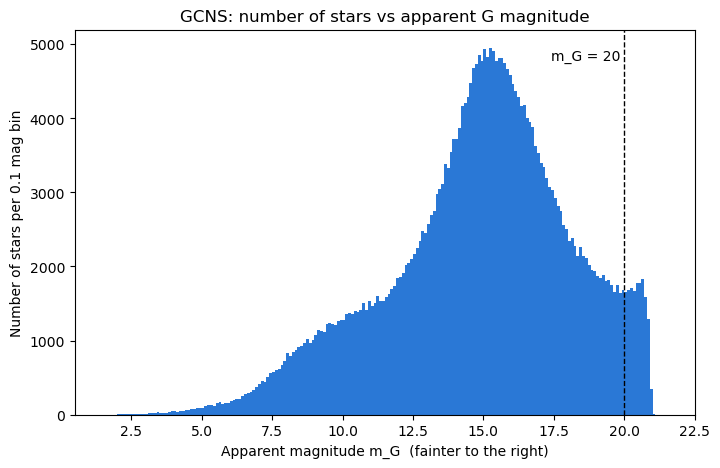

Histogram peaks in bin 15.2 to 15.3 with 4950 stars
Faintest m_G in catalogue: 21.1361


In [80]:
bins = np.arange(1.5, 21.6, 0.1)          # 0.1 mag wide bins

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["gmag"], bins=bins, color="#2a78d6")
ax.axvline(20, color="black", linestyle="--", linewidth=1)
ax.text(19.85, ax.get_ylim()[1] * 0.95, "m_G = 20", ha="right", va="top")
ax.set_xlabel("Apparent magnitude m_G  (fainter to the right)")
ax.set_ylabel("Number of stars per 0.1 mag bin")
ax.set_title("GCNS: number of stars vs apparent G magnitude")
plt.show()

counts, edges = np.histogram(df["gmag"], bins=bins)
peak = np.argmax(counts)
print(f"Histogram peaks in bin {edges[peak]:.1f} to {edges[peak+1]:.1f} with {counts[peak]} stars")
print("Faintest m_G in catalogue:", df["gmag"].max())

## Which stars can Gaia see at each distance?

This plot shows distance against absolute magnitude. Each coloured line shows the distance at which a star of a given `M_G` would have a fixed apparent magnitude, from `d = 10**((m - M + 5)/5)`.

A star that is intrinsically faint drops below Gaia's limit at a smaller distance. For the faintest stars, the edge of the data therefore follows a line of nearly constant apparent magnitude instead of reaching the catalogue's distance limit. Stars with `M_G` from 15 to 16 still reach 125 pc, and the maximum distance only falls in the 16 to 17 bin, so the dotted line at `M_G` = 15 sits on the safe side of that edge.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["M_G"], df["d"], s=0.1, color="#52514e", alpha=0.3, rasterized=True)

M_line = np.linspace(-2, 22, 500)
line_colours = {18: "#eb6834", 20: "#1baf7a", 22: "#6250d6"}
for m, colour in line_colours.items():
    d_line = 10 ** ((m - M_line + 5) / 5)
    ax.plot(M_line, d_line, color=colour, linewidth=2,
            label=f"line of constant m_G = {m}")

ax.axhline(100, color="black", linestyle=":", linewidth=1)
ax.axvline(15, color="black", linestyle=":", linewidth=1)

ax.legend(loc="lower left")
ax.set_xlim(-2, 22)
ax.set_ylim(0, 130)
ax.set_xlabel("Absolute magnitude M_G  (intrinsically fainter to the right)")
ax.set_ylabel("Distance d = 1000 / parallax  (pc)")
ax.set_title("GCNS: distance vs absolute magnitude")
plt.show()

## Volume-limited sample

A volume-limited sample aims to include every star of a chosen brightness inside a fixed volume, so that its counts aren't biased towards stars that are easy to see. This cell keeps stars with `M_G < 15` and `d < 100` pc.

At 100 pc, `M_G = gmag - 5`. Any star with `M_G < 15` inside 100 pc therefore has `gmag < 20`, which is brighter than Gaia's limit. Fainter stars are only seen out to smaller distances, so including them would leave the sample incomplete.

Two caveats:
- A few very bright nearby stars are too bright for good Gaia measurements, so they may be missing.
- This cut uses `d = 1000 / parallax`, but the `x`, `y`, `z` columns are based on `dist50`. A small number of stars in `sample` therefore sit just outside 100 pc in `x`, `y`, `z`.

In [82]:
print("Stars with d > 100 pc (to be removed):", (df["d"] > 100).sum())

sample = df[(df["M_G"] < 15) & (df["d"] < 100)].copy()
print("Volume-limited sample (M_G < 15 and d < 100 pc):", len(sample))

Stars with d > 100 pc (to be removed): 28952
Volume-limited sample (M_G < 15 and d < 100 pc): 288918


## Step (a): sky plot of the sample

This cell plots every star in `sample` on a map of the whole sky, as a sanity check before we use distances.

Right ascension (RA) and declination (Dec) work like longitude and latitude on the sky, measured from Earth's equator. The Milky Way's disk is tilted relative to that equator, so it would appear as a curved band rather than a straight line. We are inside the disk and only looking out to 100 pc, so any band should be much weaker than in a usual Milky Way image.

The map uses the Hammer projection because it preserves area. RA increases to the right here, which is the opposite of many sky maps, but that doesn't affect this check.

What to look for:
- **Coverage:** Gaia observes the whole sky, so there should be no large gaps.
- **Stripes:** these would suggest an effect of how Gaia scans the sky rather than real structure.
- **Clumps:** star clusters such as the Hyades, in Taurus, may appear as small dense patches.

This plot has no distance information, so stars that look close together here may be far apart in space. That is the limitation the 3D search is meant to remove.

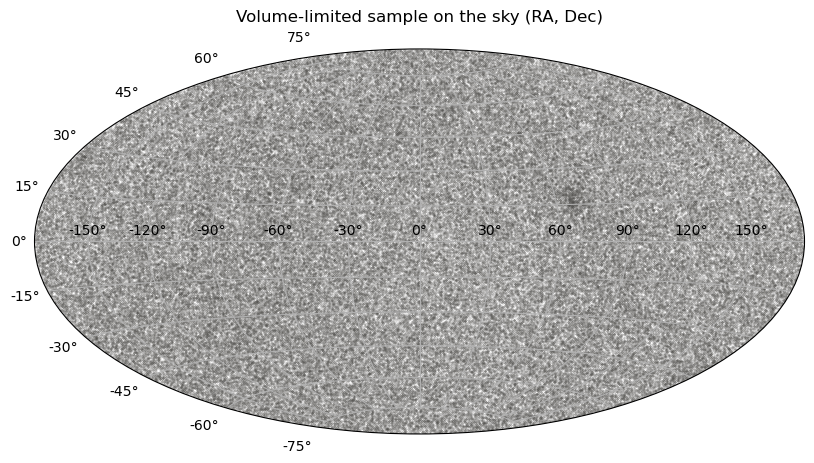

Stars plotted: 288918
Wrapped RA runs from -180.00 to 180.00 deg


In [83]:
# Sky plot of the sample. RA runs 0..360 deg, but matplotlib's sky maps
# expect longitude from -180..180 deg, in radians.
ra_wrapped = np.where(sample["ra"] > 180, sample["ra"] - 360, sample["ra"])
lon = np.radians(ra_wrapped)
lat = np.radians(sample["dec"])

# The Hammer projection preserves area, so the density of dots is fair to judge by eye.
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(projection="hammer")
ax.scatter(lon, lat, s=0.1, color="#52514e", alpha=0.3, rasterized=True)
ax.grid(True)
ax.set_title("Volume-limited sample on the sky (RA, Dec)", pad=20)
plt.show()

# Check the conversion: wrapped RA should stay between -180 and 180 deg.
print("Stars plotted:", len(sample))
print(f"Wrapped RA runs from {ra_wrapped.min():.2f} to {ra_wrapped.max():.2f} deg")

## Step (b): density and typical separation

This cell works out how crowded the sample is and how far apart its stars typically are. That distance gives us a natural scale for choosing the linking length in the graph: stars much closer together than this may be a real group rather than an average patch of space.

The number density is `N / V`, the number of stars per cubic parsec. Its inverse, `V / N`, is the volume each star has to itself on average. We turn that volume into a distance in two ways:

- **Sphere:** set `V/N = (4/3) pi r^3`, then take `2r`, the distance between the centres of two touching spheres.
- **Cube:** set `V/N = R^3`, so `R` is the side of a cube holding one star.

Both results are proportional to `(V/N)^(1/3)`:

- `R = (V/N)^(1/3)`
- `2r = 2 * (3 / (4 pi))^(1/3) * (V/N)^(1/3)`

So the two estimates differ only by a fixed number that comes from geometry, not from the data. The printed ratio should equal `2 * (3 / (4 pi))^(1/3)`.

Two caveats:
- This is the density of stars with `M_G < 15`, not of all stars, because fainter stars were cut.
- It's an average for the whole sphere. Stars aren't spread evenly, and clusters are much denser than average, which is why a graph can find them.

In [84]:
# Average density of the volume-limited sample inside the 100 pc sphere.
N = len(sample)
R_sphere = 100.0                          # pc
V = (4.0 / 3.0) * np.pi * R_sphere**3     # pc^3

density = N / V                           # stars per pc^3
volume_per_star = V / N                   # pc^3 per star

# Method 1: give each star a sphere of radius r, so V/N = (4/3) pi r^3.
# Two neighbouring spheres touch when their centres are 2r apart.
r = (3.0 * volume_per_star / (4.0 * np.pi)) ** (1.0 / 3.0)
separation_sphere = 2.0 * r

# Method 2: give each star a cube of side R, so V/N = R^3.
separation_cube = volume_per_star ** (1.0 / 3.0)

print(f"Volume of sphere: {V:.4g} pc^3")
print(f"Number density: {density:.4f} stars per pc^3")
print(f"Typical separation, sphere method (2r): {separation_sphere:.3f} pc")
print(f"Typical separation, cube method (R):   {separation_cube:.3f} pc")
print(f"Ratio of the two: {separation_sphere / separation_cube:.3f}")

Volume of sphere: 4.189e+06 pc^3
Number density: 0.0690 stars per pc^3
Typical separation, sphere method (2r): 3.025 pc
Typical separation, cube method (R):   2.438 pc
Ratio of the two: 1.241


## Step (c1): scanning the linking length

This cell builds a graph in 3D: stars are nodes, and an edge joins two stars closer than a chosen **linking length**. It then finds the connected components for nine linking lengths, from 0.2 to 1.0 times the typical separation `R` from step (b). In the printed table, `length/R` is that fraction and `length(pc)` is the linking length in parsecs.

Why scan instead of using a linking length equal to `R`? For evenly spread stars, the expected degree is `n * (4/3) pi * length^3`, where `n` is the density and `length` is the linking length. Since `n R^3 = 1`, a linking length of `R` gives an expected degree of `4 pi / 3`, about 4.19, and a linking length of `2r` gives exactly 8. Above a critical mean degree a giant component appears, as in a random graph, and it would swallow the groups we want to find. Geometric graphs need a higher mean degree than Erdos-Renyi graphs because a star's neighbours tend to be neighbours of each other.

Each linking length is also run on a **random comparison**: the same number of points spread evenly through the same sphere. Small groups appear by chance even in random points, so a real group needs to be bigger or more common than chance would produce.

What to look for:
- **Giant component:** the linking length at which the largest component suddenly jumps in size.
- **Real versus random:** real stars linking up much sooner would point to clustering. The second-largest component is a good place to look for a structure such as the Hyades.

Three caveats:
- **Distance errors:** these are a large share of the linking length for some stars, so some edges between more distant stars will be unreliable.
- **Edge of the sample:** a group near 100 pc can be cut off by the sphere's boundary.
- **Meaning of a component:** it is a group of stars close together now. Showing that they belong together needs velocities, which is the purpose of Stage 2.

In [85]:
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def component_sizes(positions, linking_length):
    """Link all pairs closer than linking_length. Return the number of
    edges and the size of each connected component, largest first."""
    # The KD-tree finds nearby pairs without checking every pair of stars.
    tree = cKDTree(positions)
    pairs = tree.query_pairs(r=linking_length, output_type="ndarray")

    # Stars are nodes and each close pair is an edge.
    n_stars = len(positions)
    edges = np.ones(len(pairs))
    graph = coo_matrix((edges, (pairs[:, 0], pairs[:, 1])), shape=(n_stars, n_stars))

    n_components, labels = connected_components(graph, directed=False)
    sizes = np.sort(np.bincount(labels))[::-1]
    return len(pairs), sizes

# Real stars: Galactic Cartesian positions in pc.
real_positions = sample[["x", "y", "z"]].to_numpy()

# Random comparison: draw points in a cube, keep those inside the sphere,
# then use the first N. A fixed seed gives the same points on every run.
rng = np.random.default_rng(42)
points = rng.uniform(-R_sphere, R_sphere, size=(3 * N, 3))
inside = np.sum(points**2, axis=1) < R_sphere**2
random_positions = points[inside][:N]

print("length/R  length(pc)  | real: degree  largest   2nd | random: degree  largest   2nd")
for fraction in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    linking_length = fraction * separation_cube

    real_edges, real_sizes = component_sizes(real_positions, linking_length)
    random_edges, random_sizes = component_sizes(random_positions, linking_length)

    # Every edge touches two stars, so mean degree = 2 * edges / stars.
    real_degree = 2 * real_edges / N
    random_degree = 2 * random_edges / N

    print(f"{fraction:8.1f}  {linking_length:10.3f}  | {real_degree:11.3f} {real_sizes[0]:8d} {real_sizes[1]:5d}"
          f" | {random_degree:13.3f} {random_sizes[0]:8d} {random_sizes[1]:5d}")

length/R  length(pc)  | real: degree  largest   2nd | random: degree  largest   2nd
     0.2       0.488  |       0.138       17    12 |         0.033        4     4
     0.3       0.732  |       0.237       67    13 |         0.113        5     5
     0.4       0.975  |       0.405      130    16 |         0.267        9     8
     0.5       1.219  |       0.671      200    60 |         0.520       12    11
     0.6       1.463  |       1.060      436    68 |         0.901       22    22
     0.7       1.707  |       1.599      728   106 |         1.424       59    56
     0.8       1.951  |       2.310     1400   278 |         2.121      240   217
     0.9       2.195  |       3.221   133803  3245 |         3.018   195106   612
     1.0       2.438  |       4.352   267613    62 |         4.132   274423    58


## Step (c2): identifying the largest groups

The scan in step (c1) showed that the giant component appears between `length/R` = 0.8 and 0.9, and that real stars form much larger groups than random points at shorter linking lengths. This cell uses a linking length of `0.5 R`, which is far from that transition, and lists the ten largest components.

For each group it prints:
- **component:** the group's position when sorted by size, so 1 is the largest.
- **stars:** the number of stars in the component.
- **d_centre:** the distance of the group's centre from the Sun, in pc.
- **median_radius** and **max_radius:** how far members sit from the group's centre, in pc.
- **RA** and **Dec:** the sky position of the star nearest the centre, in degrees. RA runs from 0 to 360 here.

The largest component in the random points gives a simple chance level. A real component bigger than that is unlikely to be chance, but this is only one random draw, so it is a rough guide rather than a formal test.

If the largest group is the Hyades, its central star should land near the dark clump on the sky plot, at about RA +65 deg, Dec +15 deg as read by eye. This is an independent check because the graph never used the sky plot. A match would support that identification but would not prove it.

Step (c4) checks whether the main results also hold for other linking lengths, so the conclusion does not depend on one choice.

In [86]:
def component_labels(positions, linking_length):
    """Return the connected component number of every star."""
    tree = cKDTree(positions)
    pairs = tree.query_pairs(r=linking_length, output_type="ndarray")
    n_stars = len(positions)
    edges = np.ones(len(pairs))
    graph = coo_matrix((edges, (pairs[:, 0], pairs[:, 1])), shape=(n_stars, n_stars))
    n_components, labels = connected_components(graph, directed=False)
    return labels

chosen_linking_length = 0.5 * separation_cube

labels = component_labels(real_positions, chosen_linking_length)
sizes = np.bincount(labels)

# The largest random group sets a simple chance level for this one random draw.
random_labels = component_labels(random_positions, chosen_linking_length)
chance_level = np.bincount(random_labels).max()

above_chance = sizes > chance_level
print(f"Linking length: {chosen_linking_length:.3f} pc")
print(f"Largest random component: {chance_level} stars")
print(f"Real components larger than that: {above_chance.sum()}")
print(f"Stars in those components: {sizes[above_chance].sum()}")
print()

# Components are numbered by size: 1 is the largest, 2 the second largest, and so on.
print("component  stars  d_centre  median_radius  max_radius     RA      Dec")
largest_first = np.argsort(sizes)[::-1]

for number, component_id in enumerate(largest_first[:10], start=1):
    member_rows = np.where(labels == component_id)[0]
    member_positions = real_positions[member_rows]

    # Centre of the group, its distance from the Sun, and how far members
    # sit from the centre. All are in pc.
    centre = member_positions.mean(axis=0)
    d_centre = np.sqrt(np.sum(centre**2))
    radii = np.sqrt(np.sum((member_positions - centre)**2, axis=1))

    # Report the sky position of the star nearest the centre. Averaging RA
    # directly would go wrong for a group that crosses RA = 0.
    central_star = sample.iloc[member_rows[np.argmin(radii)]]

    print(f"{number:9d} {sizes[component_id]:6d} {d_centre:9.1f} {np.median(radii):14.2f}"
          f" {radii.max():11.2f} {central_star['ra']:7.1f} {central_star['dec']:8.1f}")

Linking length: 1.219 pc
Largest random component: 12 stars
Real components larger than that: 10
Stars in those components: 391

component  stars  d_centre  median_radius  max_radius     RA      Dec
        1    200      47.1           2.54        4.99    66.6     15.6
        2     60      43.4           2.63        7.22    67.3     18.7
        3     29      85.3           1.57        2.53   185.8     26.0
        4     19      48.7           2.16        3.12    67.7     22.1
        5     15      98.6           0.43        1.38   130.6    -79.0
        6     15      95.3           1.26        2.31   247.5     19.2
        7     14      94.1           1.68        2.25    82.3     48.1
        8     13      51.9           1.44        2.64    12.5    -43.0
        9     13      78.0           1.62        2.87   219.2      8.3
       10     13      51.2           1.34        2.34   236.1     17.9


## Step (c3): do the groups move together?

Stars born in the same cluster move through space together, so a real cluster should have very similar `U`, `V`, `W` velocities. Unrelated stars passing nearby should not. The graph used only positions, so this is an independent test of the five largest groups.

For the whole sample and each group, this cell prints:
- **with_v:** how many stars have measured velocities.
- **U_med, V_med, W_med:** the median velocity in each direction, in km/s.
- **typical_offset:** the median distance of a star's velocity from the group's median velocity, in km/s.

Medians are used because a few unrelated stars or bad velocities would strongly affect a mean.

What to look for:
- A real cluster should have a `typical_offset` far smaller than the whole sample's.
- If components 2 and 4 are part of the Hyades, their median `U`, `V`, `W` should be close to the largest component's.
- Component 3 should also have a small `typical_offset` if it is a real group.

Only some stars have velocities, mostly brighter ones, so this subsample is not random or complete. Small groups may have very few, so check `with_v` before trusting a row. This is a check on the 3D groups, not the 6D search planned for Stage 2.

In [87]:
# Do the stars in each group move together? The graph used only positions,
# so velocities are an independent test.
velocity_columns = ["u", "v", "w"]

def velocity_summary(stars):
    """Return the number of stars with velocities, their median velocity,
    and the typical offset from that median in km/s."""
    with_velocity = stars[stars["u"].notna()]
    n_velocity = len(with_velocity)
    if n_velocity == 0:
        return 0, [np.nan, np.nan, np.nan], np.nan

    median_velocity = with_velocity[velocity_columns].median().to_numpy()
    offsets = with_velocity[velocity_columns].to_numpy() - median_velocity
    speed_offsets = np.sqrt(np.sum(offsets**2, axis=1))

    # Medians are used because a few unrelated stars or bad velocities
    # would strongly affect a mean.
    return n_velocity, median_velocity, np.median(speed_offsets)

print("group         stars  with_v    U_med    V_med    W_med  typical_offset")

n_v, median_v, offset = velocity_summary(sample)
print(f"whole sample {len(sample):6d} {n_v:7d} {median_v[0]:8.1f} {median_v[1]:8.1f}"
      f" {median_v[2]:8.1f} {offset:15.1f}")

for number, component_id in enumerate(largest_first[:5], start=1):
    members = sample[labels == component_id]
    n_v, median_v, offset = velocity_summary(members)

    # Name each group by its size order: the largest, then component 2, 3, ...
    if number == 1:
        group_name = "largest"
    else:
        group_name = f"component {number}"

    print(f"{group_name:<12s} {len(members):6d} {n_v:7d} {median_v[0]:8.1f} {median_v[1]:8.1f}"
          f" {median_v[2]:8.1f} {offset:15.1f}")

group         stars  with_v    U_med    V_med    W_med  typical_offset
whole sample 288918   80144    -10.8    -17.9     -7.4            34.8
largest         200      99    -42.1    -19.2     -1.2             1.0
component 2      60      28    -42.2    -19.2     -1.5             2.1
component 3      29      22     -2.6     -5.6     -0.7             1.0
component 4      19      10    -39.9    -19.3     -1.4             8.2
component 5      15       7    -12.2    -18.0     -9.8             1.7


## Step (c4): does the result depend on the linking length?

So far the groups come from one linking length, `0.5 R` = 1.219 pc. This cell follows the two main groups for linking lengths from `0.3 R` to `0.7 R`, so we can see whether the conclusions depend on that choice.

The components found with a linking length of `0.5 R` are numbered by size: the largest component, then component 2, component 3 and so on. That numbering changes when the linking length changes, so each group is followed through one fixed **reference star**, the star nearest its centre at `0.5 R`.

For each linking length, the cell prints:
- **stars** and **with_v:** the size of the group containing the reference star, and how many of its stars have velocities.
- **typical_offset:** how closely the group's stars move together, in km/s, as in step (c3).
- **has_component_2** and **has_component_4:** whether the reference stars of components 2 and 4 have joined this group.

What to look for:
- If components 2 and 4 join the largest component at a longer linking length while `typical_offset` stays small, that supports them being part of the Hyades.
- If `typical_offset` grows quickly as the linking length increases, the group is picking up unrelated stars, which shows how long the linking length can be before the result stops being trustworthy.

At short linking lengths, a reference star might not be linked to its main group, so a very small size there would not mean the group has vanished.

In [88]:
def central_row(component_id):
    """Return the row number of the star nearest a component's centre."""
    member_rows = np.where(labels == component_id)[0]
    member_positions = real_positions[member_rows]
    centre = member_positions.mean(axis=0)
    radii = np.sqrt(np.sum((member_positions - centre)**2, axis=1))
    return member_rows[np.argmin(radii)]

# One reference star for each of the four largest groups found at 0.5 R.
largest_component_row = central_row(largest_first[0])
component_2_row = central_row(largest_first[1])
component_3_row = central_row(largest_first[2])
component_4_row = central_row(largest_first[3])

print("length/R  length(pc)  group        stars  with_v  typical_offset  has_component_2  has_component_4")
for fraction in [0.3, 0.4, 0.5, 0.6, 0.7]:
    linking_length = fraction * separation_cube
    scan_labels = component_labels(real_positions, linking_length)

    # Follow each group through its reference star.
    for group_name, reference_row in [("largest", largest_component_row),
                                      ("component 3", component_3_row)]:
        component_id = scan_labels[reference_row]
        members = sample[scan_labels == component_id]
        n_v, median_v, offset = velocity_summary(members)

        has_component_2 = scan_labels[component_2_row] == component_id
        has_component_4 = scan_labels[component_4_row] == component_id

        print(f"{fraction:8.1f}  {linking_length:10.3f}  {group_name:<12s}{len(members):6d} {n_v:7d}"
              f" {offset:15.1f} {str(has_component_2):>16s} {str(has_component_4):>16s}")

length/R  length(pc)  group        stars  with_v  typical_offset  has_component_2  has_component_4
     0.3       0.732  largest         67      40             0.8            False            False
     0.3       0.732  component 3      1       1             0.0            False            False
     0.4       0.975  largest        130      71             1.0            False            False
     0.4       0.975  component 3      8       5             1.7            False            False
     0.5       1.219  largest        200      99             1.0            False            False
     0.5       1.219  component 3     29      22             1.0            False            False
     0.6       1.463  largest        436     196             1.3             True             True
     0.6       1.463  component 3     68      38             1.0            False            False
     0.7       1.707  largest        728     309             2.6             True             True
     0.7  

## Figure: where the graph found groups

This repeats the sky plot from step (a), with all stars in light grey and the five largest groups found with a linking length of `0.5 R` = 1.219 pc drawn on top.

The names describe what steps (c3) and (c4) showed, not confirmed identities:
- **Hyades main group** and **Hyades secondary group** (the largest component and component 2) move together to within about 1-2 km/s and merge into one group at a linking length of `0.6 R`.
- **Near Hyades, mixed motions** (component 4) also merges at `0.6 R`, but its velocities are less tightly grouped.
- **Coma Ber candidate** (component 3) is tightly grouped in velocity but moves differently from the Hyades.
- **Compact candidate** (component 5) is tight, but only 7 of its stars have velocities.

The plot has no distance information, so it shows where the groups are on the sky, not how far away they are. Near the poles the map squeezes longitudes together, so component 5, at RA 130.6 deg and Dec -79.0 deg, appears close to the RA = 30 deg line. The identities still need checking against a published source.

In [ ]:
# Sky plot with the five largest groups found at 0.5 R highlighted.
# Each group gets its own colour AND marker shape, so the legend works
# without relying on colour alone. Colours are from the Okabe-Ito palette,
# which is designed to stay distinct for colour-blind readers.
groups = [
    # (position in largest_first, legend label, colour, marker)
    (0, "Largest component: Hyades main group",     "#D55E00", "o"),
    (1, "Component 2: Hyades secondary group",      "#E69F00", "s"),
    (3, "Component 4: near Hyades, mixed motions",  "#CC79A7", "^"),
    (2, "Component 3: Coma Ber candidate",          "#0072B2", "D"),
    (4, "Component 5: compact candidate",           "#009E73", "v"),
]

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection="hammer")

# All stars in light grey as the background.
ax.scatter(lon, lat, s=0.1, color="#c8c8c8", alpha=0.3, rasterized=True)

# Each group on top. A thin white edge keeps overlapping markers separate.
for index, label, colour, marker in groups:
    in_group = labels == largest_first[index]
    ax.scatter(lon[in_group], lat[in_group], s=18, color=colour, marker=marker,
               edgecolors="white", linewidths=0.4, label=label)

ax.grid(True)
ax.set_title(f"Groups found by the 3D graph (linking length = {chosen_linking_length:.3f} pc)", pad=20)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2,
          frameon=False, markerscale=1.5)
plt.show()